# Bonus: Cvičenie 2 — predikcia výroby elektriny v Nemecku

Cieľom je z dvojročných 15-minútových dát vytvoriť denný časový rad celkovej výroby elektriny a porovnať **SARIMA** s **SARIMAX** rozšíreným o dve exogénne premenné. Modely sa učia na období január 2024 až máj 2025 a hodnotia na nezávislom horizonte **jún až december 2025**.

Denná výroba je vyjadrená v MWh: každé 15-minútové pozorovanie v MW násobíme 0,25 h. Sezónna perióda `s=7` zodpovedá týždennému rytmu pracovných dní a víkendov.

## 1. Importy a načítanie dát

In [1]:
from pathlib import Path
import csv
from itertools import islice
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
DATA_DIR = Path('data')
FILES = [
    DATA_DIR / 'energy-charts_Public_net_electricity_generation_in_Germany_in_2024.csv',
    DATA_DIR / 'energy-charts_Public_net_electricity_generation_in_Germany_in_2025.csv',
]

def load_energy_csv(path):
    # Súbory sa líšia počtom úvodných poznámok; nájdeme skutočný riadok hlavičky.
    with open(path, encoding='utf-8-sig', newline='') as handle:
        preview = list(islice(csv.reader(handle), 5))
    header_row = next(i for i, row in enumerate(preview) if row and row[0] == 'Date (GMT+1)')
    columns = preview[header_row]
    df = pd.read_csv(path, skiprows=header_row + 2, header=None, names=columns)
    df['timestamp'] = pd.to_datetime(df['Date (GMT+1)'], utc=True).dt.tz_localize(None)
    return df.drop(columns=['Date (GMT+1)'])

raw = pd.concat([load_energy_csv(path) for path in FILES], ignore_index=True)
raw = raw.sort_values('timestamp').drop_duplicates('timestamp').set_index('timestamp')
print(f'Počet 15-minútových pozorovaní: {len(raw):,}')
print(f'Rozsah: {raw.index.min()} — {raw.index.max()}')
raw.head()

Počet 15-minútových pozorovaní: 70,176
Rozsah: 2023-12-31 23:00:00 — 2025-12-31 22:45:00


,Hydro pumped storage consumption,Hydro Run-of-River,Biomass,Fossil brown coal / lignite,Fossil hard coal,Fossil oil,Fossil coal-derived gas,Fossil gas,Geothermal,Hydro water reservoir,Hydro pumped storage,Others,Waste,Wind offshore,Wind onshore,Solar,Load,Renewable share of generation,Day Ahead Auction (DE-LU)
timestamp,,,,,,,,,,,,,,,,,,,
2023-12-31 23:00:00,-1550.0,2375.1,4098.2,3314.0,1566.0,398.4,595.0,2558.2,20.2,138.8,755.8,152.4,828.3,5842.2,29299.4,0.0,40592.6,82.4,0.10
2023-12-31 23:15:00,-1923.0,2370.6,4093.3,3436.9,1572.5,397.6,410.9,2410.6,20.1,160.0,410.9,152.4,835.1,5751.1,28957.4,0.0,40301.1,82.6,0.10
2023-12-31 23:30:00,-2261.2,2371.1,4092.6,3340.2,1567.0,397.8,410.9,2410.6,20.2,144.6,449.2,152.4,827.1,5621.3,28963.8,0.0,40171.7,82.7,0.10
2023-12-31 23:45:00,-2358.8,2378.7,4094.7,3318.9,1577.4,398.4,406.0,2392.2,20.2,132.7,342.2,152.4,805.0,5515.1,29205.5,0.0,39615.0,82.8,0.10
2024-01-01 00:00:00,-2990.4,2380.1,4071.3,3322.8,1572.5,398.0,408.6,2399.6,20.0,132.9,483.1,152.4,804.6,5467.0,29226.7,0.0,39336.8,82.8,0.01


## 2. Konštrukcia denného cieľa a exogénnych premenných

Do cieľa zahrnieme všetky výrobné zdroje. **Hydro pumped storage consumption** je spotreba pri čerpaní, preto ju nezapočítame; `Load`, podiel obnoviteľných zdrojov a cena nie sú výrobné zdroje. Ako exogénne premenné zvolíme:

- **Load** — dopyt po elektrine, ktorý priamo ovplyvňuje potrebnú úroveň výroby a skladbu dispatchu;
- **Day Ahead Auction (DE-LU)** — trhová cena, ktorá sumarizuje napätie medzi dopytom a ponukou a ekonomické stimuly pre výrobu.

V tomto spätnom teste používame skutočné denné hodnoty exogénnych premenných v testovacom období. V reálnej prevádzke by ich bolo potrebné najprv samostatne predikovať.

In [2]:
non_generation = {
    'Hydro pumped storage consumption', 'Load',
    'Renewable share of generation', 'Day Ahead Auction (DE-LU)'
}
generation_cols = [c for c in raw.columns if c not in non_generation and c != 'timestamp']
for col in generation_cols + ['Load', 'Day Ahead Auction (DE-LU)']:
    raw[col] = pd.to_numeric(raw[col], errors='coerce')

daily = pd.DataFrame(index=raw.resample('D').size().index)
daily['generation_mwh'] = raw[generation_cols].sum(axis=1).resample('D').sum(min_count=1) * 0.25
daily['load_mw_mean'] = raw['Load'].resample('D').mean()
daily['price_eur_mwh_mean'] = raw['Day Ahead Auction (DE-LU)'].resample('D').mean()
daily = daily.asfreq('D').dropna()
print('Výrobné stĺpce:', ', '.join(generation_cols))
print(f'Denných pozorovaní: {len(daily)}; chýbajúce hodnoty: {daily.isna().sum().sum()}')
daily.describe().round(2)

Výrobné stĺpce: Hydro Run-of-River, Biomass, Fossil brown coal / lignite, Fossil hard coal, Fossil oil, Fossil coal-derived gas, Fossil gas, Geothermal, Hydro water reservoir, Hydro pumped storage, Others, Waste, Wind offshore, Wind onshore, Solar
Denných pozorovaní: 732; chýbajúce hodnoty: 0


,generation_mwh,load_mw_mean,price_eur_mwh_mean
count,732.00,732.00,732.00
mean,1158370.73,53067.90,83.80
std,188245.06,6359.42,35.29
min,51107.40,37484.60,-1.02
25%,1021241.06,49236.58,62.79
50%,1133352.52,53126.85,84.30
75%,1289541.41,57445.99,100.01
max,1738510.00,67302.88,395.66


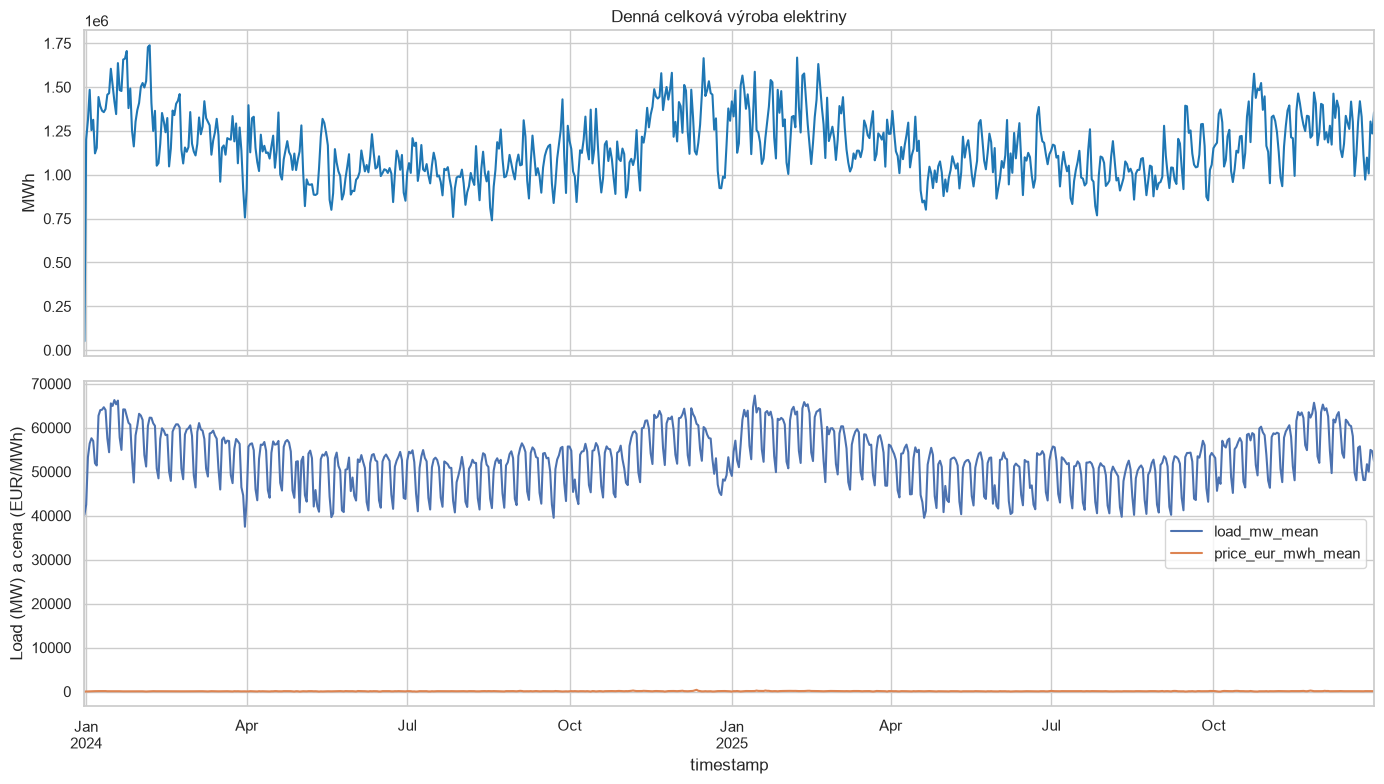

,generation_mwh,load_mw_mean,price_eur_mwh_mean
generation_mwh,1.000,0.748,0.009
load_mw_mean,0.748,1.000,0.493
price_eur_mwh_mean,0.009,0.493,1.000


Korelácie podporujú voľbu exogénnych premenných, ale samy osebe nedokazujú kauzalitu.


In [3]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
daily['generation_mwh'].plot(ax=axes[0], color='tab:blue', title='Denná celková výroba elektriny')
axes[0].set_ylabel('MWh')
daily[['load_mw_mean', 'price_eur_mwh_mean']].plot(ax=axes[1])
axes[1].set_ylabel('Load (MW) a cena (EUR/MWh)')
plt.tight_layout()
plt.show()

corr = daily[['generation_mwh', 'load_mw_mean', 'price_eur_mwh_mean']].corr()
display(corr.round(3))
print('Korelácie podporujú voľbu exogénnych premenných, ale samy osebe nedokazujú kauzalitu.')

## 3. Časové rozdelenie a špecifikácia modelov

Nezamieňame náhodne pozorovania: všetky dni do 31. 5. 2025 patria do tréningu a dni od 1. 6. 2025 do testu. Použijeme rovnakú špecifikáciu pre férové porovnanie:

$$SARIMA(1,1,1)(1,1,1)_7$$

Denný rad obsahuje trend/ročnú zmenu aj týždennú sezónnosť. Diferencovanie `d=1` a sezónne diferencovanie `D=1` odstránia ne-stacionárne zložky; AR a MA členy zachytia krátkodobú závislosť. Pri 214-dňovom teste súhlasí aj praktické hľadisko: porovnávame predikcie na celom požadovanom horizonte, nie iba jednodňový rolling forecast.

In [4]:
train_end = pd.Timestamp('2025-05-31')
test_start = pd.Timestamp('2025-06-01')
test_end = pd.Timestamp('2025-12-31')
y = daily['generation_mwh']
exog = daily[['load_mw_mean', 'price_eur_mwh_mean']]
y_train, y_test = y.loc[:train_end], y.loc[test_start:test_end]
x_train, x_test = exog.loc[:train_end], exog.loc[test_start:test_end]
print(f'Tréning: {y_train.index.min().date()} — {y_train.index.max().date()} ({len(y_train)} dní)')
print(f'Test:    {y_test.index.min().date()} — {y_test.index.max().date()} ({len(y_test)} dní)')

Tréning: 2023-12-31 — 2025-05-31 (518 dní)
Test:    2025-06-01 — 2025-12-31 (214 dní)


## 4. Odhad SARIMA a SARIMAX

In [5]:
order = (1, 1, 1)
seasonal_order = (1, 1, 1, 7)

sarima = SARIMAX(
    y_train, order=order, seasonal_order=seasonal_order,
    enforce_stationarity=False, enforce_invertibility=False
).fit(disp=False)

sarimax = SARIMAX(
    y_train, exog=x_train, order=order, seasonal_order=seasonal_order,
    enforce_stationarity=False, enforce_invertibility=False
).fit(disp=False)

sarima_pred = sarima.get_forecast(steps=len(y_test)).predicted_mean
sarimax_pred = sarimax.get_forecast(steps=len(y_test), exog=x_test).predicted_mean
sarima_pred.index = y_test.index
sarimax_pred.index = y_test.index
display(pd.DataFrame({'SARIMA': sarima_pred, 'SARIMAX': sarimax_pred}).head())

,SARIMA,SARIMAX
timestamp,,
2025-06-01,9.089201e+05,9.781657e+05
2025-06-02,1.062571e+06,1.114415e+06
2025-06-03,1.096736e+06,1.181667e+06
2025-06-04,1.110589e+06,1.212953e+06
2025-06-05,1.091891e+06,1.194122e+06


## 5. Presnosť na testovacom období

MAPE počítame s malou toleranciou v menovateli; cieľové hodnoty sú však kladné, takže v tomto datasete nevzniká praktický problém s nulou.

In [6]:
def metrics(actual, predicted):
    error = actual - predicted
    return {
        'MAE (MWh)': np.mean(np.abs(error)),
        'RMSE (MWh)': np.sqrt(np.mean(error ** 2)),
        'MAPE (%)': np.mean(np.abs(error / np.maximum(np.abs(actual), 1e-9))) * 100,
    }

comparison = pd.DataFrame({
    'SARIMA': metrics(y_test, sarima_pred),
    'SARIMAX': metrics(y_test, sarimax_pred),
}).T
display(comparison.round(2))
best = comparison['RMSE (MWh)'].idxmin()
print(f'Najlepší model podľa RMSE: {best}')

,MAE (MWh),RMSE (MWh),MAPE (%)
SARIMA,176226.77,232348.80,14.21
SARIMAX,112129.71,129022.72,10.17


Najlepší model podľa RMSE: SARIMAX


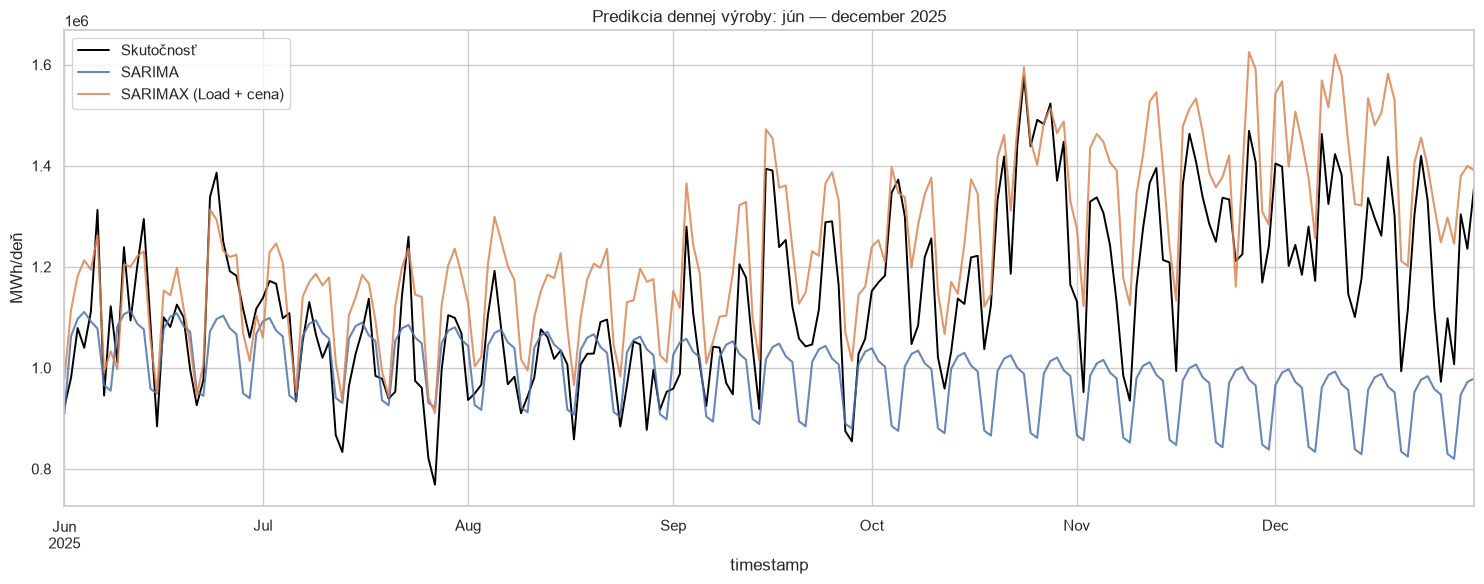

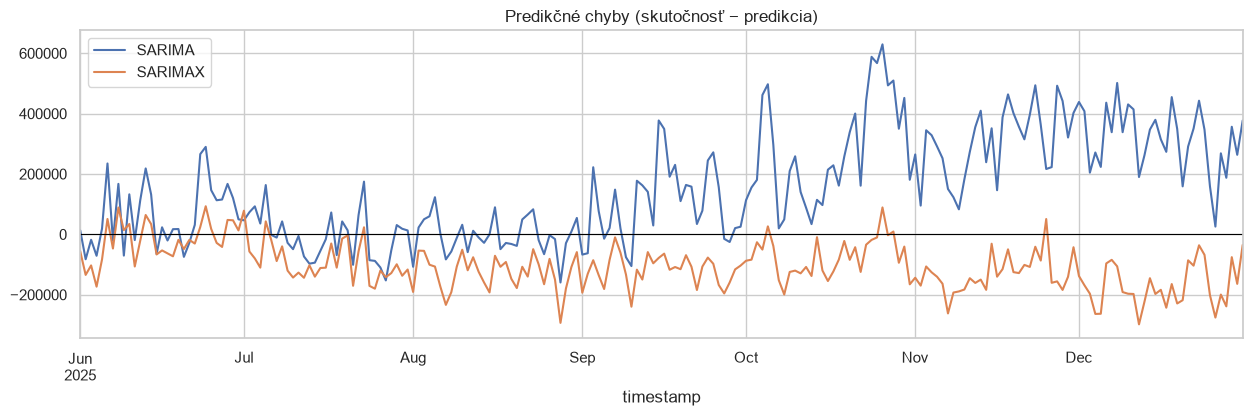

In [7]:
fig, ax = plt.subplots(figsize=(15, 6))
y_test.plot(ax=ax, color='black', linewidth=1.4, label='Skutočnosť')
sarima_pred.plot(ax=ax, label='SARIMA', alpha=.85)
sarimax_pred.plot(ax=ax, label='SARIMAX (Load + cena)', alpha=.85)
ax.set_title('Predikcia dennej výroby: jún — december 2025')
ax.set_ylabel('MWh/deň')
ax.legend()
plt.tight_layout()
plt.show()

errors = pd.DataFrame({'SARIMA': y_test - sarima_pred, 'SARIMAX': y_test - sarimax_pred})
errors.plot(figsize=(15, 4), title='Predikčné chyby (skutočnosť − predikcia)')
plt.axhline(0, color='black', linewidth=.8)
plt.show()

## 6. Diagnostika rezíduí a záver

Dobrý model by mal mať rezíduá približne bez autokorelácie. Ljung–Box test pri vyššom p-value neposkytuje dôkaz zostávajúcej sériovej závislosti (nie je to dôkaz, že rezíduá sú dokonale biele).

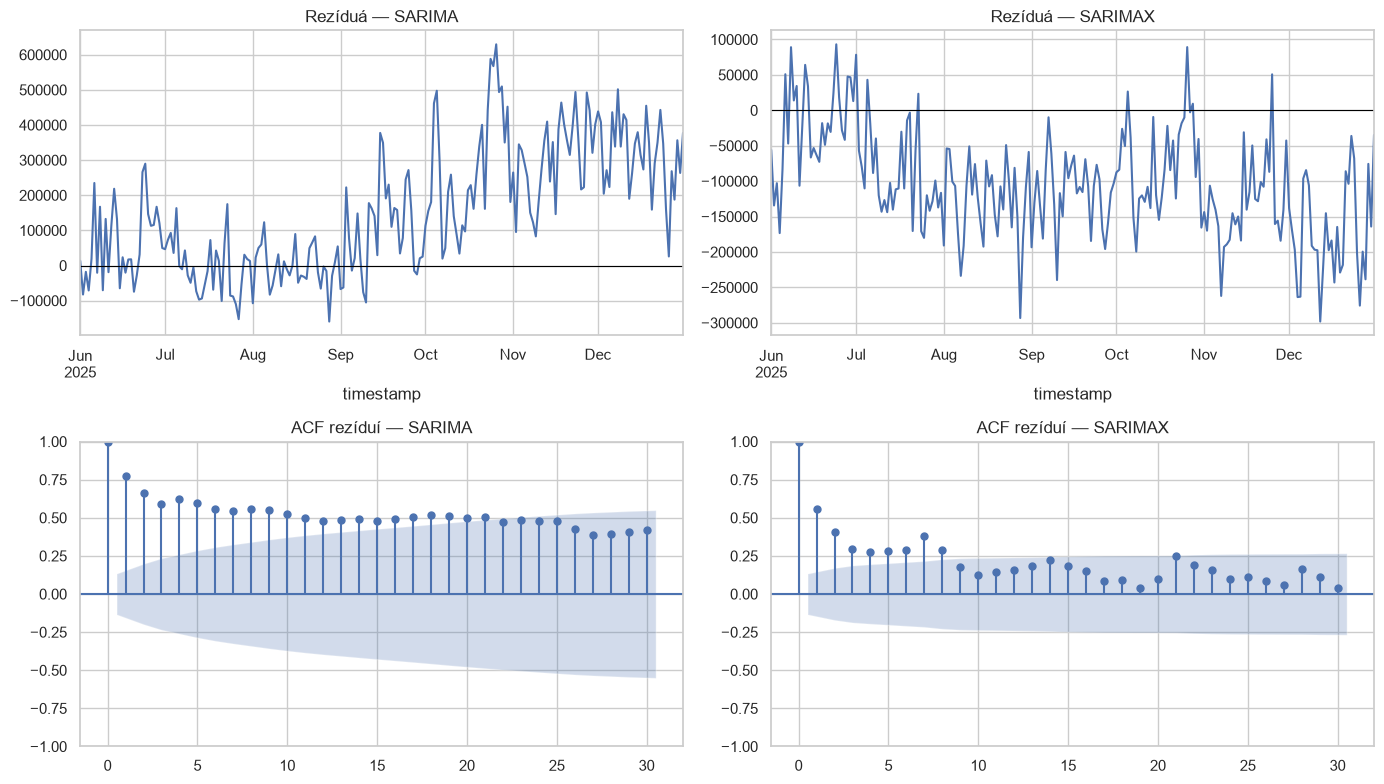

,SARIMA,SARIMAX
7,0.0,0.0
14,0.0,0.0


Záver: podľa RMSE je lepší model SARIMAX. SARIMAX má pridanú informáciu o dennom dopyte a trhovej cene; zlepšenie však treba interpretovať ako retrospektívny test so známymi exogénnymi hodnotami.


In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, name in zip(axes[0], errors.columns):
    errors[name].plot(ax=ax, title=f'Rezíduá — {name}')
    ax.axhline(0, color='black', linewidth=.8)
for ax, name in zip(axes[1], errors.columns):
    plot_acf(errors[name].dropna(), lags=30, ax=ax, title=f'ACF rezíduí — {name}')
plt.tight_layout()
plt.show()

ljung_box = pd.DataFrame({
    name: acorr_ljungbox(errors[name].dropna(), lags=[7, 14], return_df=True)['lb_pvalue']
    for name in errors.columns
})
display(ljung_box.round(4))
print(
    f'Záver: podľa RMSE je lepší model {best}. SARIMAX má pridanú informáciu o dennom dopyte '
    'a trhovej cene; zlepšenie však treba interpretovať ako retrospektívny test so známymi exogénnymi hodnotami.'
)
